In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df = pd.read_csv("Salary_data.csv")
df.drop(columns="Unnamed: 0", inplace=True)
df.head()

C:\Users\navee\AppData\Local\Temp\ipykernel_27332\2225479310.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns="Unnamed: 0", inplace=True)


,YearsExperience,Salary
0,1.2,39344
1,1.4,46206
2,1.6,37732
3,2.1,43526
4,2.3,39892


In [11]:
df.describe()

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.413333,76004.000000
std,2.837888,27414.429785
min,1.200000,37732.000000
25%,3.300000,56721.750000
50%,4.800000,65238.000000
75%,7.800000,100545.750000
max,10.600000,122392.000000


In [12]:
df.shape

(30, 2)

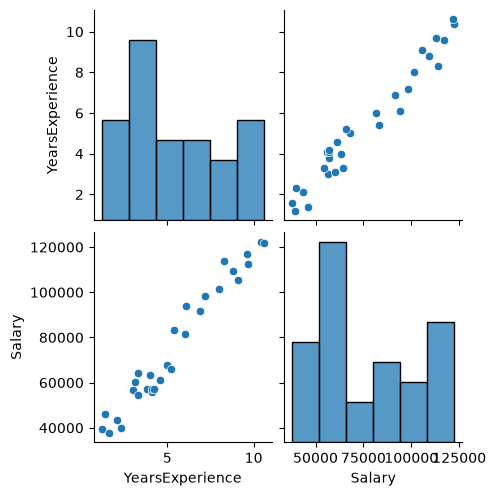

In [13]:
sns.pairplot(df)

<Axes: xlabel='Salary', ylabel='Count'>

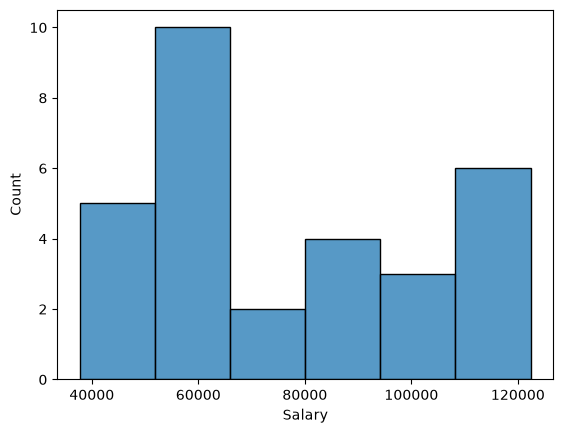

In [14]:
sns.histplot(df['Salary'])

<Axes: >

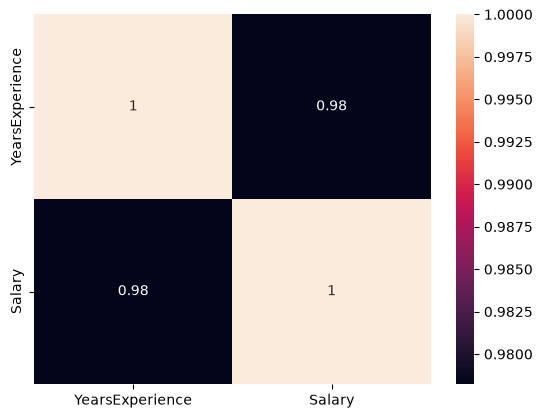

In [15]:
sns.heatmap(df.corr('pearson', numeric_only=True), annot=True)

In [16]:
df.columns

Index(['YearsExperience', 'Salary'], dtype='str')

In [18]:
X = df.drop(columns=["Salary"])
y = df["Salary"]

In [19]:
X.head()

,YearsExperience
0,1.2
1,1.4
2,1.6
3,2.1
4,2.3


In [20]:
y.head()

0    39344
1    46206
2    37732
3    43526
4    39892
Name: Salary, dtype: int64

In [21]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

In [22]:
print("shape of train X", X_train.shape)
print("shape of train y", y_train.shape)
print("shape of test X", X_test.shape)
print("shape of Test y", y_test.shape)

shape of train X (24, 1)
shape of train y (24,)
shape of test X (6, 1)
shape of Test y (6,)


In [23]:
from sklearn.linear_model import LinearRegression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[9423.82]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['YearsExperience']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.438e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [24]:
y_pred = lr_model.predict(X_test)

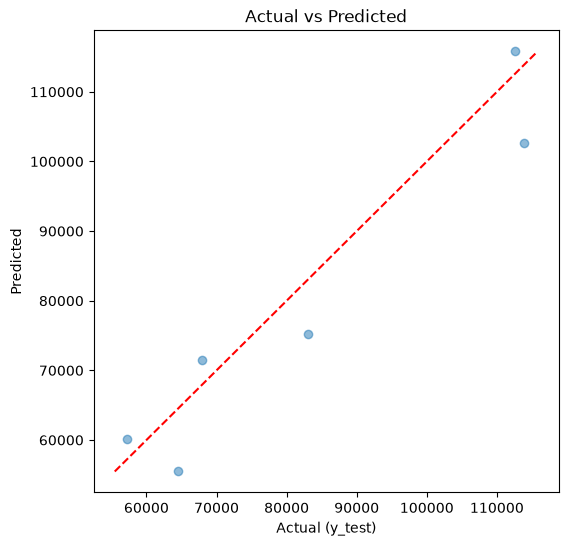

In [25]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.5)
lims = [min(y_test.min(), y_pred.min()),max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, color="red", linestyle="--")
plt.xlabel("Actual (y_test)")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.show()

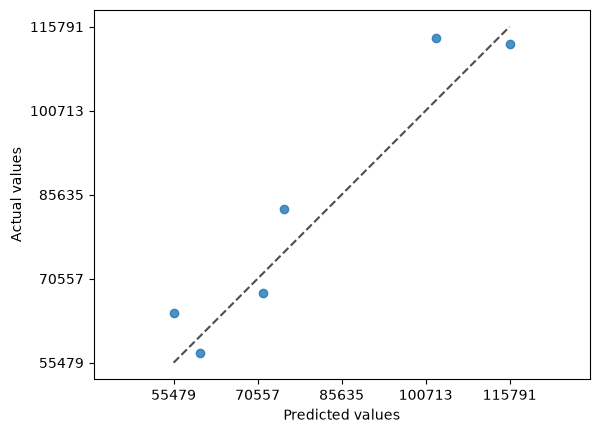

In [26]:
from sklearn.metrics import PredictionErrorDisplay

PredictionErrorDisplay.from_predictions(y_test, y_pred, kind="actual_vs_predicted")
plt.show()


In [27]:
from sklearn import metrics

print("MAE", metrics.mean_absolute_error(y_test, y_pred))

MAE 6286.453830757743


In [28]:
print ('MSE',metrics.mean_squared_error(y_test,y_pred))

MSE 49830096.855908364


In [29]:
from sklearn.model_selection import KFold, cross_validate

def cross_validate_model(model, X, y, cv=5):
    kf = KFold(n_splits=cv, random_state=42, shuffle=True)
    scores = cross_validate(
        model, X, y, cv=kf,
        scoring={
            "r2": "r2",
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
        }
    )
    print(f"R2   : {scores['test_r2'].mean():.3f} (+/- {scores['test_r2'].std():.3f})")
    print(f"MAE  : {-scores['test_mae'].mean():.3f}")
    print(f"RMSE : {-scores['test_rmse'].mean():.3f}")
    return scores

In [30]:
scores = cross_validate_model(lr_model, X_train, y_train)

R2   : 0.946 (+/- 0.036)
MAE  : 4572.624
RMSE : 5530.824
